In [93]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# LOAD DATA
getdata = pd.read_csv("ecommerce_business_data.csv")
print("DATA EXPLORATION")
print("*************************************************************")
print(f"Shape of the Data: {getdata.shape}")
print("First 10 Records:")
print(getdata.head(10))
print("Last 10 Records")
print(getdata.tail(10))
print("DATA INFORMATION:")
print("---------------------------------------")
print(getdata.info())
print("Data Description:")
print("---------------------------------------")
print(getdata.describe())
print("Data Types")
print("---------------------------------------")
print(getdata.dtypes)
print("DATA CLEANING")
print("*************************************************************")

totalrows = len(getdata)
print(f"Total Number Of Rows: {totalrows}")
totalnullrows = getdata.isnull().sum()
print(f"Total Missing Values per Column:\n{totalnullrows}")
nullpercentage = (totalnullrows / totalrows) * 100
print(f"Percentage of Missing Values per Column:\n{nullpercentage}")
#Dropna
dropped_data = getdata.dropna()
print("Dropped Rows with Missing Values:")
print("---------------------------------------")
print(dropped_data)
print("Dropped data Count")
print("---------------------------------------")
print(dropped_data.isnull().sum())
print("Dropping Duplicates")
print("---------------------------------------")
print(getdata.duplicated)
#Duplicated count
print("Duplicated Count")
print("---------------------------------------")
print(getdata.duplicated().sum())

# print("Duplicated Count based on customer_id")
# print("---------------------------------------")
# print(getdata.duplicated(subset=["customer_id"]).sum())

# print("Dropping Duplicates based on customer_id")
# print("---------------------------------------")
# getdata_no_duplicates = getdata.drop_duplicates(subset=["customer_id"])
# print(getdata_no_duplicates)
print("After Dropping Duplicates")
print("---------------------------------------")
getdata.drop_duplicates(inplace=True)
print(getdata)
print(getdata.shape)

print("DATA MANIPULATION")
print("*************************************************************")

# Preprocessing data to handle blank elements safely
getdata['discount_pct'] = getdata['discount_pct'].fillna(0)
getdata['quantity'] = getdata['quantity'].fillna(1)
print("After Fillna")
print("---------------------------------------")
print(getdata.shape)

# 2. Financial Metrics Calculations
getdata['gross_revenue'] = getdata['unit_price'] * getdata['quantity']
getdata['discount_value_lost'] = getdata['gross_revenue'] * getdata['discount_pct']

# Filter specifically for heavy discount threshold leaks (>10%)
heavy_discount_filter = getdata['discount_pct'] > 0.10
getdata_heavy_leaks = getdata[heavy_discount_filter]

total_gross = getdata['gross_revenue'].sum()
total_lost = getdata['discount_value_lost'].sum()
heavy_leak_total = getdata_heavy_leaks['discount_value_lost'].sum()

print("--- FINANCIAL DIAGNOSTIC REPORT ---")
print(f"Total Portfolio Gross Revenue : ₹{total_gross:,.2f}")
print(f"Overall Revenue Lost to Discounts: ₹{total_lost:,.2f}")
print(f"Revenue Lost to Heavy Leakage (>10%): ₹{heavy_leak_total:,.2f}")
print(f"Heavy Leaks Proportion of Total Losses: {(heavy_leak_total / total_lost) * 100:.2f}%")
      
#Only COD Payment Method
condition = getdata["payment_method"] == "COD"
cod_data = getdata[condition]
print("COD Payment Method Data")
print("---------------------------------------")
print(cod_data)

#profit orders in and condition
# The dataset does not contain a cost column.
# Use net sales as a profit proxy unless product cost is available.
getdata["profit"] = getdata["net_sales_amount"]

# Electronics orders with profit greater than 500
profit_list = getdata[
    (getdata["category"] == "Electronics") &
    (getdata["profit"] > 500)
]
print("Profit List Greater than 500")
print("-----------------------------------------")
print(profit_list)

#between
midrevenue = getdata[getdata['profit'].between(50,2000)]
print("Profit product list from 50 to 2000")
print("-----------------------------------------")
print(midrevenue)
print("SORTING")
print("***********************************************")
#Product Amount asc
prdbyasc = getdata.sort_values("net_sales_amount")
print("Product amount by ascending order")
print("--------------------------------")
print(prdbyasc)
prdbydesc = getdata.sort_values("net_sales_amount",ascending=False)
print("Product amount by descending order")
print("--------------------------------")
print(prdbydesc)


condition = getdata["category"] == "Electronics"
electronics_data = getdata[condition]
print("Electronics Category Data")
print("---------------------------------------")
print(electronics_data)

#top 10 larget order by amount
top_10_largest_orders = getdata.nlargest(10, "net_sales_amount")
print("Top 10 Largest Orders by Amount")
print("---------------------------------------")
print(top_10_largest_orders)

#GroupBY
total_amount_by_category = getdata.groupby("category")["net_sales_amount"].sum()
print("Total Amount by Category")
print("---------------------------------------")
print(total_amount_by_category)

# Aggregate Net Sales and Quantity by Category
category_data = (
    getdata.groupby("category")[["net_sales_amount", "quantity"]]
    .sum()
    .reset_index()
)

DATA EXPLORATION
*************************************************************
Shape of the Data: (5000, 14)
First 10 Records:
       order_id           order_date customer_id      segment       city  \
0  ORD-20260000  2025-09-10 05:27:55   CUST-2123  Home Office    Kolkata   
1  ORD-20260001  2025-09-10 08:15:25   CUST-1620    Corporate      Delhi   
2  ORD-20260002  2025-09-10 12:06:25   CUST-2196     Consumer    Chennai   
3  ORD-20260003  2025-09-10 13:36:24   CUST-1161  Home Office    Kolkata   
4  ORD-20260004  2025-09-10 13:38:35   CUST-1775     Consumer  Ahmedabad   
5  ORD-20260005  2025-09-10 16:58:07   CUST-1273     Consumer     Jaipur   
6  ORD-20260006  2025-09-10 17:52:03   CUST-2026     Consumer  Hyderabad   
7  ORD-20260007  2025-09-10 18:47:41   CUST-2051    Corporate    Lucknow   
8  ORD-20260008  2025-09-10 19:37:20   CUST-1325     Consumer     Mumbai   
9  ORD-20260009  2025-09-10 21:10:18   CUST-1939     Consumer       Pune   

           state                cate

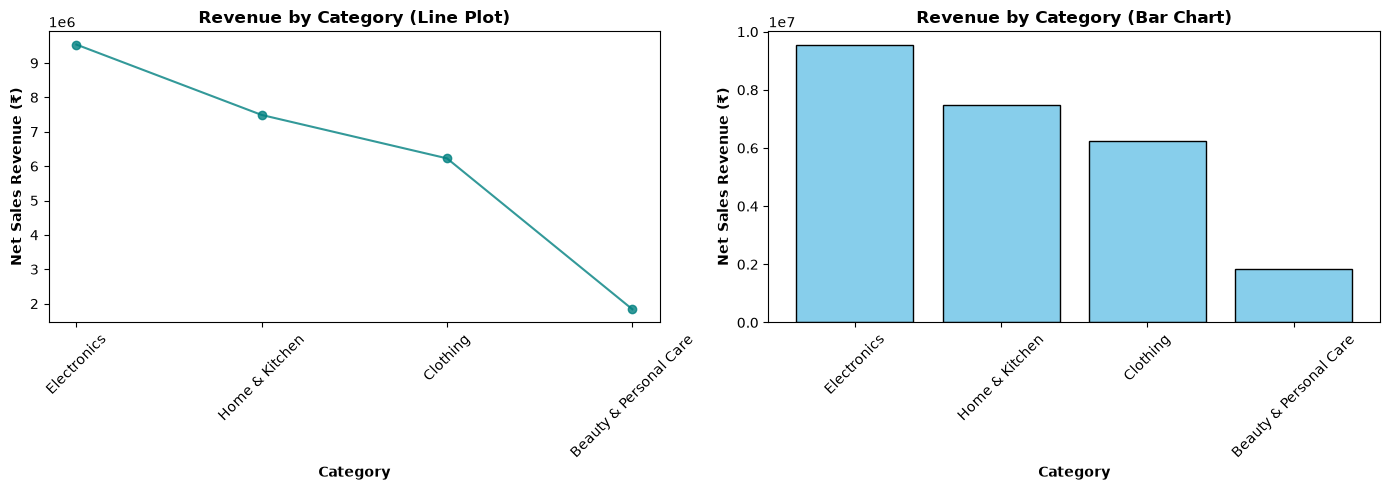

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# Load data if not already loaded
if "getdata" not in globals():
    getdata = pd.read_csv("ecommerce_business_data.csv")

# Group by category
category_sales = (
    getdata.groupby("category")["net_sales_amount"]
    .sum()
    .reset_index()
    .sort_values("net_sales_amount", ascending=False)
)

# Create subplots: 1 row, 2 columns
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Left: Line Plot ---
axes[0].plot(
    category_sales["category"],
    category_sales["net_sales_amount"],
    marker="o",
    linestyle="-",
    color="teal",
    alpha=0.8
)
axes[0].set_title("Revenue by Category (Line Plot)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Category", fontweight="bold")
axes[0].set_ylabel("Net Sales Revenue (₹)", fontweight="bold")
axes[0].tick_params(axis="x", rotation=45)

# --- Right: Bar Chart ---
axes[1].bar(
    category_sales["category"],
    category_sales["net_sales_amount"],
    color="skyblue",
    edgecolor="black"
)
axes[1].set_title("Revenue by Category (Bar Chart)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Category", fontweight="bold")
axes[1].set_ylabel("Net Sales Revenue (₹)", fontweight="bold")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


C:\Users\DELL\AppData\Local\Temp\ipykernel_7528\1191804128.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\DELL\AppData\Local\Temp\ipykernel_7528\1191804128.py:142: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\DELL\AppData\Local\Temp\ipykernel_7528\1191804128.py:154: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=getdata, x="Day_of_Week", order=days_order, palette="flare", ax=ax6)
C:\Users\DELL\AppData\Local\Temp\ipykernel_7528\1191804128.py:165: FutureWarning: 

Passing `palette` without assigning `hue` is 

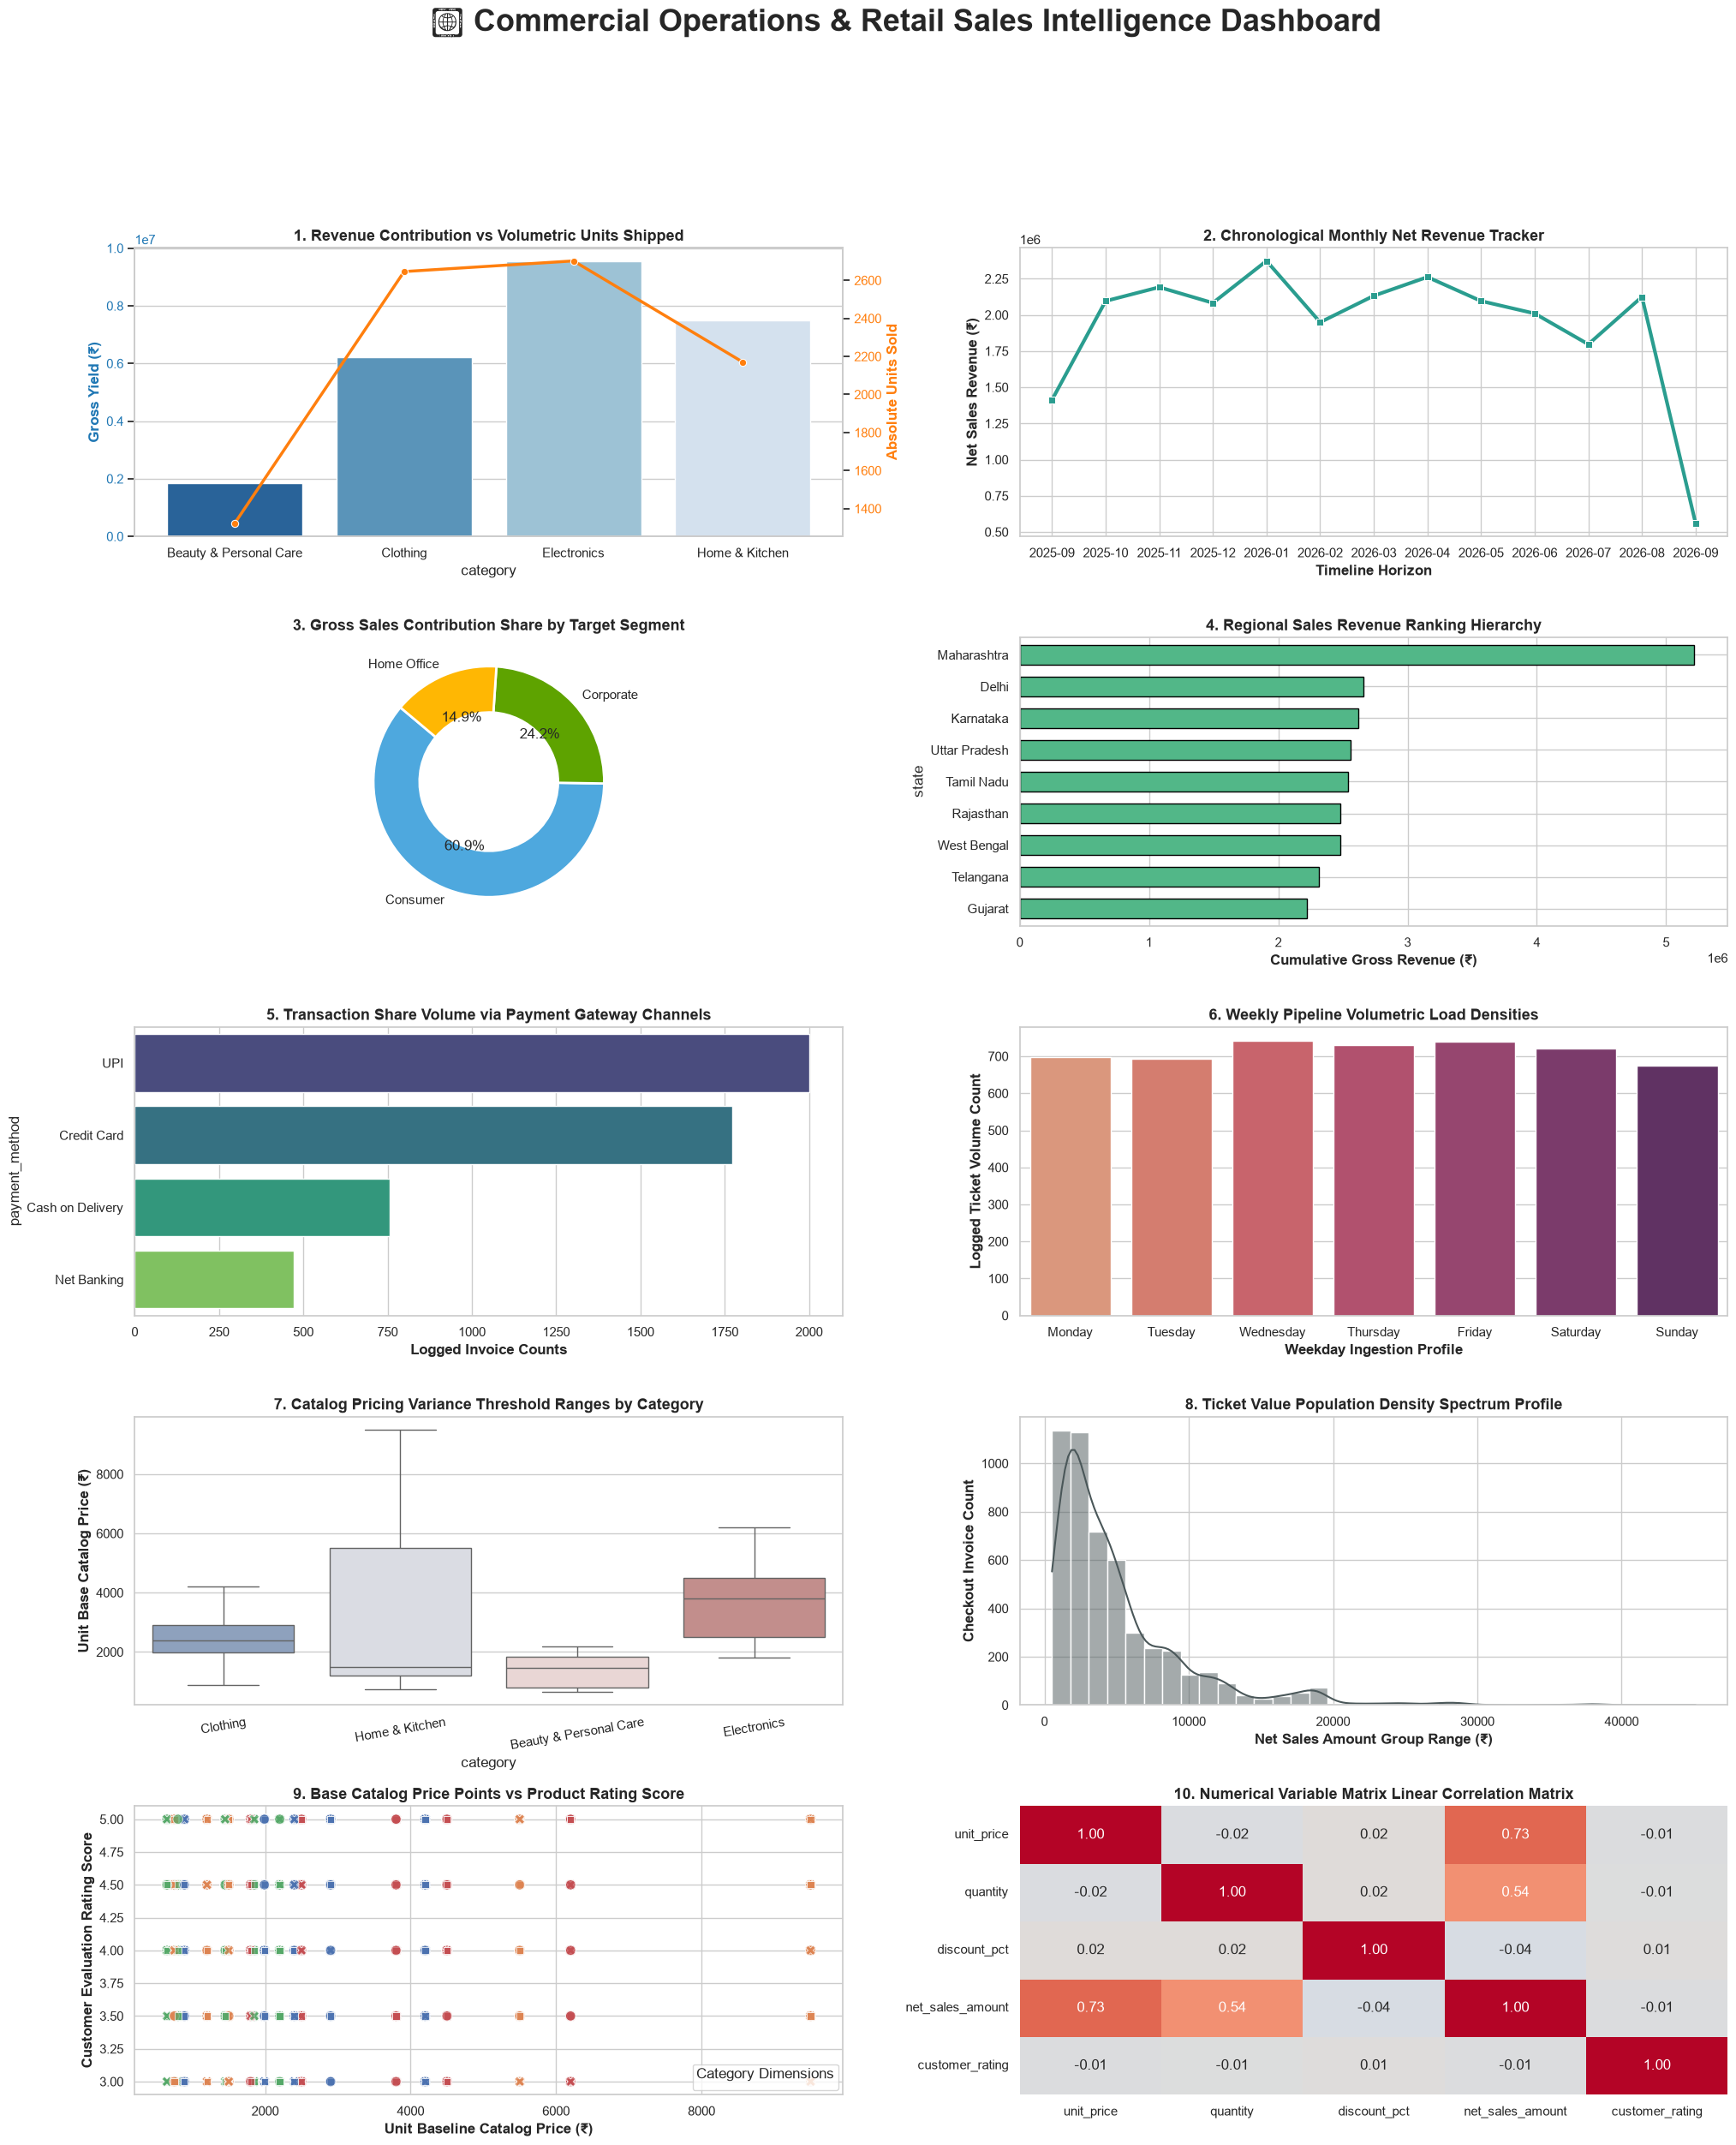

In [ ]:

#DASHBOARD1 - 10 charts  

# Chart 2: Cumulative Sales Performance over Time Series
ax2 = fig.add_subplot(gs[0, 1])
time_series = (
    getdata.groupby("Month_Year")["net_sales_amount"].sum().sort_index().reset_index()
)
sns.lineplot(
    data=time_series,
    x="Month_Year",
    y="net_sales_amount",
    marker="s",
    linewidth=3,
    color="#2a9d8f",
    ax=ax2,
)
ax2.set_title("2. Chronological Monthly Net Revenue Tracker", fontsize=13, fontweight="bold")
ax2.set_ylabel("Net Sales Revenue (₹)", fontweight="bold")
ax2.set_xlabel("Timeline Horizon", fontweight="bold")

# ==========================================
# ROW 2: MARKET SHARE & RANKINGS
# ==========================================

# Chart 3: Segment Contribution Market Donut
ax3 = fig.add_subplot(gs[1, 0])
segment_shares = getdata.groupby("segment")["net_sales_amount"].sum()
ax3.pie(
    segment_shares,
    labels=segment_shares.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=["#4ea8de", "#5ea300", "#ffb703"],
    wedgeprops=dict(width=0.4, edgecolor="w", linewidth=2),
)
ax3.set_title("3. Gross Sales Contribution Share by Target Segment", fontsize=13, fontweight="bold")

# Chart 4: Geographic Gross Revenue Distributions (Horizontal Ranking)
ax4 = fig.add_subplot(gs[1, 1])
state_rev = (
    getdata.groupby("state")["net_sales_amount"]
    .sum()
    .sort_values(ascending=True)
)

state_rev.plot(
    kind="barh",
    color="#52b788",
    ax=ax4,
    edgecolor="black",
    width=0.6,
)
#state_rev.plot(kind="barh", color="#52b788", ax=ax4, edgecolor="black", height=0.6)
ax4.set_title("4. Regional Sales Revenue Ranking Hierarchy", fontsize=13, fontweight="bold")
ax4.set_xlabel("Cumulative Gross Revenue (₹)", fontweight="bold")

# ==========================================
# ROW 3: CHECKOUT LOGISTICS & FREQUENCIES
# ==========================================

# Chart 5: Transaction Quantities by Gateway Channel
ax5 = fig.add_subplot(gs[2, 0])
sns.countplot(
    data=getdata,
    y="payment_method",
    order=getdata["payment_method"].value_counts().index,
    palette="viridis",
    ax=ax5,
)
ax5.set_title("5. Transaction Share Volume via Payment Gateway Channels", fontsize=13, fontweight="bold")
ax5.set_xlabel("Logged Invoice Counts", fontweight="bold")

# Chart 6: Order Intake Trajectory via Day of Week
ax6 = fig.add_subplot(gs[2, 1])
sns.countplot(data=getdata, x="Day_of_Week", order=days_order, palette="flare", ax=ax6)
ax6.set_title("6. Weekly Pipeline Volumetric Load Densities", fontsize=13, fontweight="bold")
ax6.set_xlabel("Weekday Ingestion Profile", fontweight="bold")
ax6.set_ylabel("Logged Ticket Volume Count", fontweight="bold")

# ==========================================
# ROW 4: DISTRIBUTION SPREAD & VARIANCE PROFILES
# ==========================================

# Chart 7: Base Unit Cost Limits by Category Matrix (Box Plot)
ax7 = fig.add_subplot(gs[3, 0])
sns.boxplot(data=getdata, x="category", y="unit_price", palette="vlag", ax=ax7)
ax7.set_title("7. Catalog Pricing Variance Threshold Ranges by Category", fontsize=13, fontweight="bold")
ax7.set_ylabel("Unit Base Catalog Price (₹)", fontweight="bold")
ax7.tick_params(axis="x", rotation=10)

# Chart 8: Ticket Population Values Frequency Spectrum (Histogram)
ax8 = fig.add_subplot(gs[3, 1])
sns.histplot(
    data=getdata, x="net_sales_amount", bins=35, kde=True, color="#4a5759", ax=ax8
)
ax8.set_title("8. Ticket Value Population Density Spectrum Profile", fontsize=13, fontweight="bold")
ax8.set_xlabel("Net Sales Amount Group Range (₹)", fontweight="bold")
ax8.set_ylabel("Checkout Invoice Count", fontweight="bold")

# ==========================================
# ROW 5: INTERACTION & SYSTEM DENSITIES
# ==========================================

# Chart 9: Base Unit Prices vs Customer Sentiment Scatter Matrix
ax9 = fig.add_subplot(gs[4, 0])
sns.scatterplot(
    data=rating_clean,
    x="unit_price",
    y="customer_rating",
    hue="category",
    legend=False,
    style="segment",
    s=70,
    alpha=0.75,
    ax=ax9,
)
ax9.set_title("9. Base Catalog Price Points vs Product Rating Score", fontsize=13, fontweight="bold")
ax9.set_xlabel("Unit Baseline Catalog Price (₹)", fontweight="bold")
ax9.set_ylabel("Customer Evaluation Rating Score", fontweight="bold")
ax9.legend(loc="lower right", title="Category Dimensions", fontsize=8)

# Chart 10: Operational Numeric Correlation Interactions Matrix
ax10 = fig.add_subplot(gs[4, 1])
num_getdata = getdata[
    [
        "unit_price",
        "quantity",
        "discount_pct",
        "net_sales_amount",
        "customer_rating",
    ]
].corr()
sns.heatmap(
    num_getdata,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    cbar=False,
    ax=ax10,
)
ax10.set_title("10. Numerical Variable Matrix Linear Correlation Matrix", fontsize=13, fontweight="bold")

# ==========================================
# 3. SAVE & DISPLAY INFRASTRUCTURE
# ==========================================
plt.tight_layout()
plt.show()


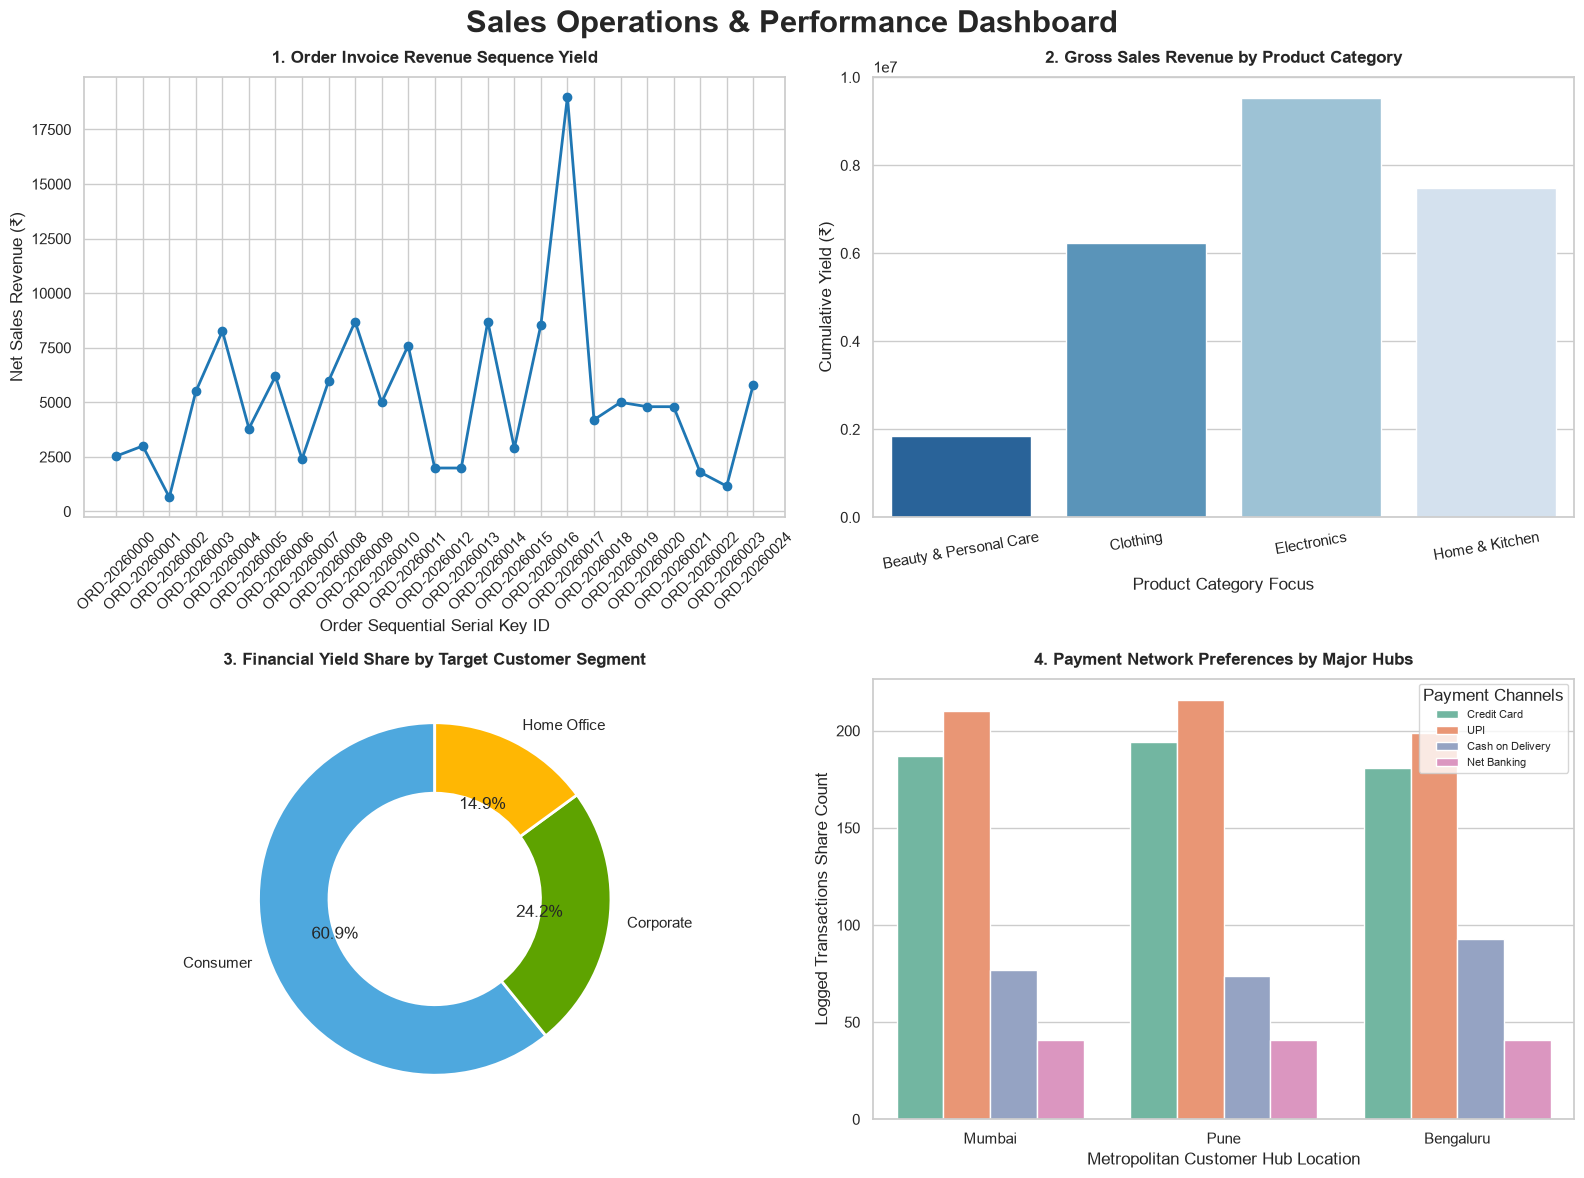

In [64]:
#DASHBOARD 2 - 4 charts
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 12))
fig.suptitle(
    "Sales Operations & Performance Dashboard",
    fontsize=22,
    fontweight="bold",
    y=0.98,
)

ax1, ax2 = axes[0, 0], axes[0, 1]  
ax3, ax4 = axes[1, 0], axes[1, 1] 

# Line Chart of Net Sales Amount by Order Sequence
getdata_sorted = getdata.sort_values(by="order_date")
ax1.plot(
    getdata_sorted["order_id"].head(25),
    getdata_sorted["net_sales_amount"].head(25),
    color="#1f77b4",
    marker="o",
    linewidth=2,
)
ax1.set_title("1. Order Invoice Revenue Sequence Yield", fontweight="bold", pad=10)
ax1.set_xlabel("Order Sequential Serial Key ID")
ax1.set_ylabel("Net Sales Revenue (₹)")
ax1.tick_params(axis="x", rotation=45)

# Bar Chart of Total Net Sales Amount by Product Category

cat_sales = getdata.groupby("category")["net_sales_amount"].sum().reset_index()
sns.barplot(
    data=cat_sales,
    x="category",
    y="net_sales_amount",
    hue="category",
    palette="Blues_r",
    legend=False,
    ax=ax2,
)
ax2.set_title("2. Gross Sales Revenue by Product Category", fontweight="bold", pad=10)
ax2.set_xlabel("Product Category Focus")
ax2.set_ylabel("Cumulative Yield (₹)")
ax2.tick_params(axis="x", rotation=10)

# Donut Chart Segment Contribution 

segment_sales = getdata.groupby("segment")["net_sales_amount"].sum()
ax3.pie(
    segment_sales,
    labels=segment_sales.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#4ea8de", "#5ea300", "#ffb703"],
    wedgeprops=dict(width=0.4, edgecolor="w", linewidth=2),  # width=0.4 hollows out the pie
)
ax3.set_title("3. Financial Yield Share by Target Customer Segment", fontweight="bold", pad=10)

# Isolate top 3 cities for a clean categorical layout view

top_cities = getdata['city'].value_counts().head(3).index
city_sub_df = getdata[getdata['city'].isin(top_cities)]

sns.countplot(
    data=city_sub_df, 
    x="city", 
    hue="payment_method", 
    palette="Set2", 
    legend="False"
    ax=ax4
)
ax4.set_title("4. Payment Network Preferences by Major Hubs", fontweight="bold", pad=10)
ax4.set_xlabel("Metropolitan Customer Hub Location")
ax4.set_ylabel("Logged Transactions Share Count")
ax4.legend(title="Payment Channels", fontsize=8, loc="upper right")
plt.tight_layout() 
plt.show()

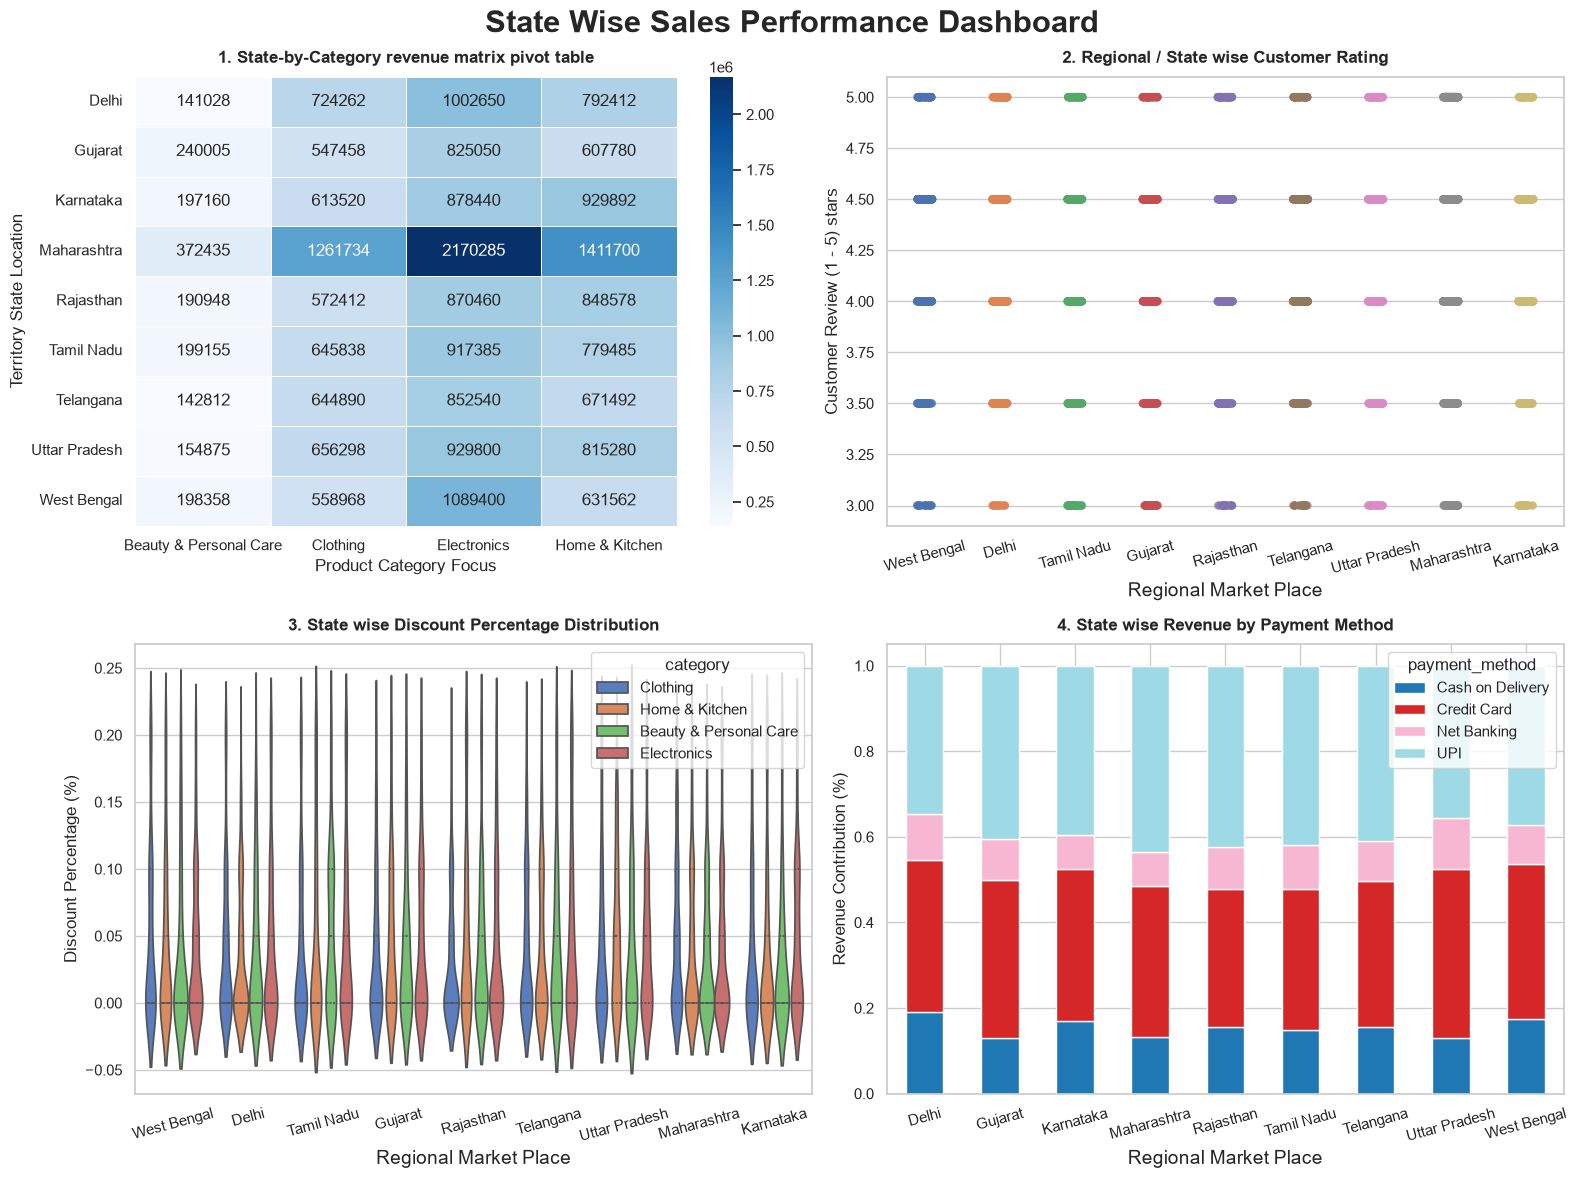

In [80]:
# Dashboard3 - 4 Charts - State wise Report
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 12)) 
fig.suptitle(
    "State Wise Sales Performance Dashboard",
    fontsize=22,
    fontweight="bold",
    y=0.98,
)
ax1, ax2 = axes[0, 0], axes[0, 1]  
ax3, ax4 = axes[1, 0], axes[1, 1] 
#chart1  heat map for - State-by-Category revenue matrix pivot table
#statewise_data = getdata.groupby("state")["net_sales_amount"].sum().reset_index()
statewise_data = getdata.pivot_table(index="state", columns="category", values="net_sales_amount", aggfunc="sum")
sns.heatmap(statewise_data, annot=True, fmt=".0f", cmap="Blues", ax=ax1,linewidths=0.5)
ax1.set_title("1. State-by-Category revenue matrix pivot table", fontweight="bold", pad=10)
ax1.set_xlabel("Product Category Focus")
ax1.set_ylabel("Territory State Location")
plt.xticks(rotation=15)
#chart2 strip plot for state-wise customer rating

sns.stripplot(data=getdata,x="state",y="customer_rating", ax=ax2,hue="state",alpha=0.7,size=6)
ax2.set_title("2. Regional / State wise Customer Rating", fontweight="bold", pad=10)
ax2.set_xlabel("Regional Market Place",fontdict={"fontsize":14})
ax2.set_ylabel("Customer Review (1 - 5) stars")
ax2.tick_params(axis="x", labelrotation=15)

#chart3 - Violin Density plot (Discount Percentage Distribution by state)
sns.violinplot(data=getdata, x="state", y="discount_pct", ax=ax3, inner="quartile", palette="muted",hue="category")
ax3.set_title("3. State wise Discount Percentage Distribution", fontweight="bold", pad=10)
ax3.set_xlabel("Regional Market Place", fontdict={"fontsize":14})
ax3.set_ylabel("Discount Percentage (%)")
ax3.tick_params(axis="x", labelrotation=15)

#chart4 - Stacked Bar Chart  - State wise Revenue by payment method 

state_payment_data = getdata.pivot_table(index="state", columns="payment_method", values="net_sales_amount", aggfunc="sum")
pay_state_percentage = state_payment_data.div(state_payment_data.sum(axis=1), axis=0)
pay_state_percentage.plot(kind="bar", stacked=True, ax=ax4, colormap="tab20")
ax4.set_title("4. State wise Revenue by Payment Method", fontweight="bold", pad=10)
ax4.set_xlabel("Regional Market Place", fontdict={"fontsize":14})
ax4.set_ylabel("Revenue Contribution (%)")
ax4.tick_params(axis="x", labelrotation=15)

plt.tight_layout()
plt.show()



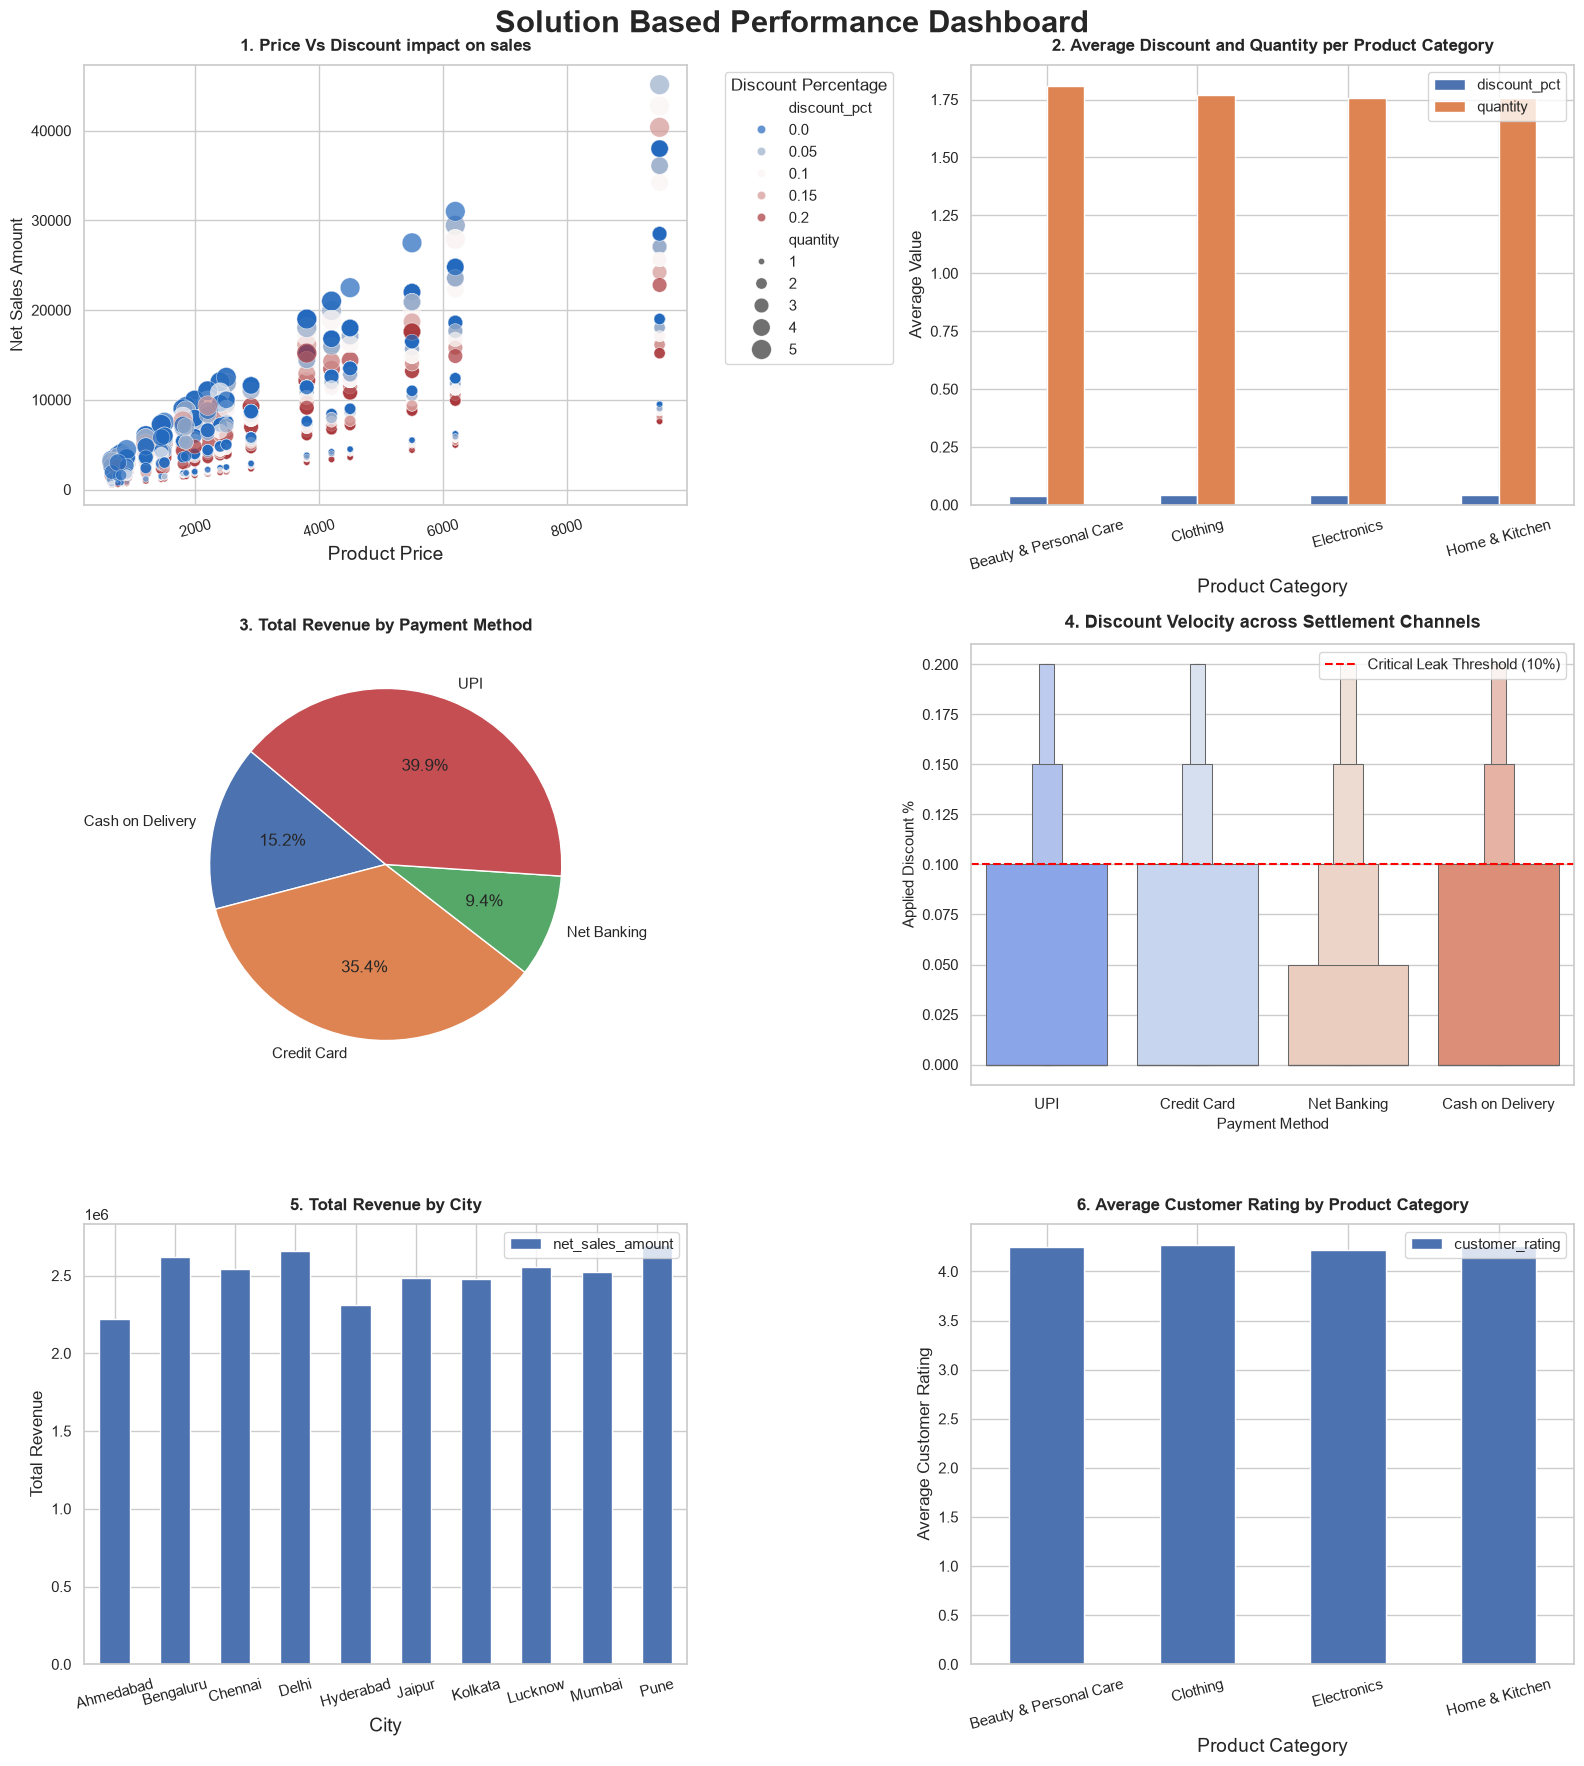

In [86]:
#Dashboard 4 - Solution Based Chart - 6 charts

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(16, 18)) 
fig.suptitle(
    "Solution Based Performance Dashboard",
    fontsize=22,
    fontweight="bold",
    y=0.98,
)
ax1, ax2 = axes[0, 0], axes[0, 1]  
ax3, ax4 = axes[1, 0], axes[1, 1] 
ax5, ax6 = axes[2, 0], axes[2, 1]

#scatter Plot - Price Vs Discount impact on sales
sns.scatterplot(data=getdata, x="unit_price", y="net_sales_amount", ax=ax1, hue="discount_pct", alpha=0.7, size="quantity",palette="vlag",sizes=(20, 200))
ax1.set_title("1. Price Vs Discount impact on sales", fontweight="bold", pad=10)
ax1.set_xlabel("Product Price", fontdict={"fontsize":14})
ax1.set_ylabel("Net Sales Amount")
ax1.legend(title="Discount Percentage", bbox_to_anchor=(1.05, 1), loc="upper left")
ax1.tick_params(axis="x", labelrotation=15)

#2. Average Discount and Quantity per Product Category (Bar Plot)
category_avg_data = getdata.groupby("category")[["discount_pct", "quantity"]].mean().reset_index()
category_avg_data.plot(kind="bar", x="category", y=["discount_pct", "quantity"], ax=ax2)
ax2.set_title("2. Average Discount and Quantity per Product Category", fontweight="bold", pad=10)
ax2.set_xlabel("Product Category", fontdict={"fontsize":14})
ax2.set_ylabel("Average Value")
ax2.tick_params(axis="x", labelrotation=15)

#3. Total Revenue by Payment Method (Pie Chart)
payment_revenue_data = getdata.groupby("payment_method")["net_sales_amount"].sum().reset_index()
ax3.pie(payment_revenue_data["net_sales_amount"], labels=payment_revenue_data["payment_method"], autopct="%1.1f%%", startangle=140)
ax3.set_title("3. Total Revenue by Payment Method", fontweight="bold", pad=10)

#4. Total Revenue by Category (Bar Plot)
# category_revenue_data = getdata.groupby("category")["net_sales_amount"].sum().reset_index()
# category_revenue_data.plot(kind="bar", x="category", y="net_sales_amount", ax=ax4)
# ax4.set_title("4. Total Revenue by Product Category", fontweight="bold", pad=10)
# ax4.set_xlabel("Product Category", fontdict={"fontsize":14})
# ax4.set_ylabel("Total Revenue")
# ax4.tick_params(axis="x", labelrotation=15)

sns.boxenplot(
    data=getdata,
    x='payment_method',
    y='discount_pct',
    palette='coolwarm',
    hue='payment_method',
    legend=False,
    ax=ax4
)

ax4.axhline(0.10, color='red', linestyle='--', linewidth=1.5, label='Critical Leak Threshold (10%)')
ax4.set_title("4. Discount Velocity across Settlement Channels", fontsize=13, pad=12, weight='bold')
ax4.set_xlabel("Payment Method", fontsize=11)
ax4.set_ylabel("Applied Discount %", fontsize=11)
ax4.legend(loc='upper right')

#5. Total Revenue by city (Bar Plot)
city_revenue_data = getdata.groupby("city")["net_sales_amount"].sum().reset_index()
city_revenue_data.plot(kind="bar", x="city", y="net_sales_amount", ax=ax5)
ax5.set_title("5. Total Revenue by City", fontweight="bold", pad=10)
ax5.set_xlabel("City", fontdict={"fontsize":14})
ax5.set_ylabel("Total Revenue")
ax5.tick_params(axis="x", labelrotation=15)

#6. Average Customer Rating by Product Category (Bar Plot)
category_rating_data = getdata.groupby("category")["customer_rating"].mean().reset_index()
category_rating_data.plot(kind="bar", x="category", y="customer_rating", ax=ax6)
ax6.set_title("6. Average Customer Rating by Product Category", fontweight="bold", pad=10)
ax6.set_xlabel("Product Category", fontdict={"fontsize":14})
ax6.set_ylabel("Average Customer Rating")
ax6.tick_params(axis="x", labelrotation=15)

plt.tight_layout()
plt.show()
